# Atividade 09 — Métodos de Suavização (KNN-regressão e Kernel Smoothing)

**Script R equivalente:** [`../scriptsR/09-metodos-suavizacao.R`](../scriptsR/09-metodos-suavizacao.R) e [`../codigo/09-metodos-suavizacao.R`](../codigo/09-metodos-suavizacao.R)

**Explicação detalhada (consolidado):** [consolidado/09-metodos-suavizacao.md](https://github.com/Megalonnix/proj_ivan_gustavo_jorge_IPDM/blob/main/consolidado/09-metodos-suavizacao.md)

**Propósito deste notebook:** permitir a execução da Atividade 09 no Google Colab (runtime R), exibindo todas as saídas e gráficos interativos inline. Diferente do script `.R`, este notebook foi concebido para reprodução na nuvem sem necessidade de configuração de ambiente local.

**Alvo:** `mortalidade_60_69`. **Preditor principal:** `riqueza` (Índice IPDM de Riqueza).

**Como rodar no Colab:** `Runtime` → `Change runtime type` → selecionar **R** → `Run all`.


In [1]:
# =============================================================
# 1. CARREGAMENTO DOS DADOS (IPDM BAIXADA SANTISTA)
# =============================================================
arquivo_local <- file.path("..", "bancoDeDados", "df_ipdm_baixada_por_municipio.csv")
url_github    <- "https://raw.githubusercontent.com/Megalonnix/proj_ivan_gustavo_jorge_IPDM/main/estrutura/bancoDeDados/df_ipdm_baixada_por_municipio.csv"
origem_dados  <- if (file.exists(arquivo_local)) arquivo_local else url_github

dados_brutos <- read.csv(origem_dados, sep = ";", dec = ",", fileEncoding = "latin1",
                         check.names = FALSE, stringsAsFactors = FALSE)

dados <- data.frame(
  municipio         = as.character(dados_brutos[[2]]),
  ano               = as.integer(dados_brutos[[3]]),
  riqueza           = as.numeric(dados_brutos[[4]]),
  longevidade       = as.numeric(dados_brutos[[5]]),
  escolaridade      = as.numeric(dados_brutos[[6]]),
  ipdm              = as.numeric(dados_brutos[[7]]),
  mortalidade_60_69 = as.numeric(dados_brutos[[8]]),
  distorcao_em      = as.numeric(dados_brutos[[9]]),
  pib_per_capita    = as.numeric(dados_brutos[[10]])
)

cat("[INFO] Dados carregados com sucesso! Total de observacoes:", nrow(dados), "\n")
head(dados)


[INFO] Dados carregados com sucesso! Total de observacoes: 54 


,municipio,ano,riqueza,longevidade,escolaridade,ipdm,mortalidade_60_69,distorcao_em,pib_per_capita
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Bertioga,2014,0.575,0.609,0.363,0.5156667,17.69156,17.26543,46417.74
2,Bertioga,2016,0.559,0.639,0.440,0.5460000,16.23510,16.45526,45937.18
3,Bertioga,2018,0.548,0.653,0.483,0.5613333,17.12161,16.79530,46417.74
4,Bertioga,2020,0.553,0.672,0.551,0.5920000,22.19854,15.07601,41444.84
5,Bertioga,2022,0.519,0.633,0.508,0.5533333,25.42855,13.30000,34785.52
6,Bertioga,2024,0.552,0.587,0.519,0.5526667,15.04526,12.50000,42939.20


In [2]:
# =============================================================
# 2. PROTOCOLO DA AULA 09 (SLIDE 26)
# =============================================================
x <- dados$riqueza
y <- dados$mortalidade_60_69
ok <- !is.na(x) & !is.na(y); x <- x[ok]; y <- y[ok]

# Modelos: KNN, Kernel Nadaraya-Watson e Reta MQO
knn_reg <- function(x0, x, y, k) mean(y[order(abs(x - x0))[1:k]])
nw      <- function(x0, x, y, h) { w <- dnorm((x - x0) / h); sum(w * y) / sum(w) }
reta    <- function(x0, x, y) sum(coef(lm(y ~ x)) * c(1, x0))

# 5 dobras para validacao cruzada consistente
set.seed(1)
dobra <- sample(rep(1:5, length = length(y)))

cv_de <- function(prever) mean(sapply(1:5, function(j) {
  tr <- dobra != j; va <- dobra == j
  mean((y[va] - sapply(x[va], prever, x = x[tr], y = y[tr]))^2)
}))

# 1. Reta MQO
cv_reta <- cv_de(reta)

# 2. KNN
ks <- c(3, 5, 10, 20, 40); ks <- ks[ks < 0.8 * length(y)]
cv_knn <- sapply(ks, function(k) cv_de(function(x0, x, y) knn_reg(x0, x, y, k)))
names(cv_knn) <- paste0("k=", ks)
melhor_k <- ks[which.min(cv_knn)]

# 3. Kernel Smoothing (Nadaraya-Watson)
hs <- sd(x) * c(0.05, 0.1, 0.2, 0.4)
cv_kernel <- sapply(hs, function(h) cv_de(function(x0, x, y) nw(x0, x, y, h)))
names(cv_kernel) <- paste0("h=", round(hs, 4))
melhor_h <- hs[which.min(cv_kernel)]

# Quadro Resumo
cat("=== RESULTADOS DA VALIDACAO CRUZADA (5 DOBRAS) ===\n")
data.frame(
  Modelo = c("Reta MQO", paste0("KNN (k=", melhor_k, ")"), paste0("Kernel NW (h=", round(melhor_h, 4), ")")),
  MSE_CV = round(c(cv_reta, min(cv_knn), min(cv_kernel)), 4),
  RMSE_CV = round(sqrt(c(cv_reta, min(cv_knn), min(cv_kernel))), 4),
  Ganho_vs_Reta = c("0.0%",
                    paste0(round(100 * (1 - min(cv_knn)/cv_reta), 2), "%"),
                    paste0(round(100 * (1 - min(cv_kernel)/cv_reta), 2), "%"))
)


=== RESULTADOS DA VALIDACAO CRUZADA (5 DOBRAS) ===


Modelo,MSE_CV,RMSE_CV,Ganho_vs_Reta
<chr>,<dbl>,<dbl>,<chr>
Reta MQO,13.4295,3.6646,0.0%
KNN (k=20),12.5767,3.5464,6.35%
Kernel NW (h=0.007),12.4573,3.5295,7.24%


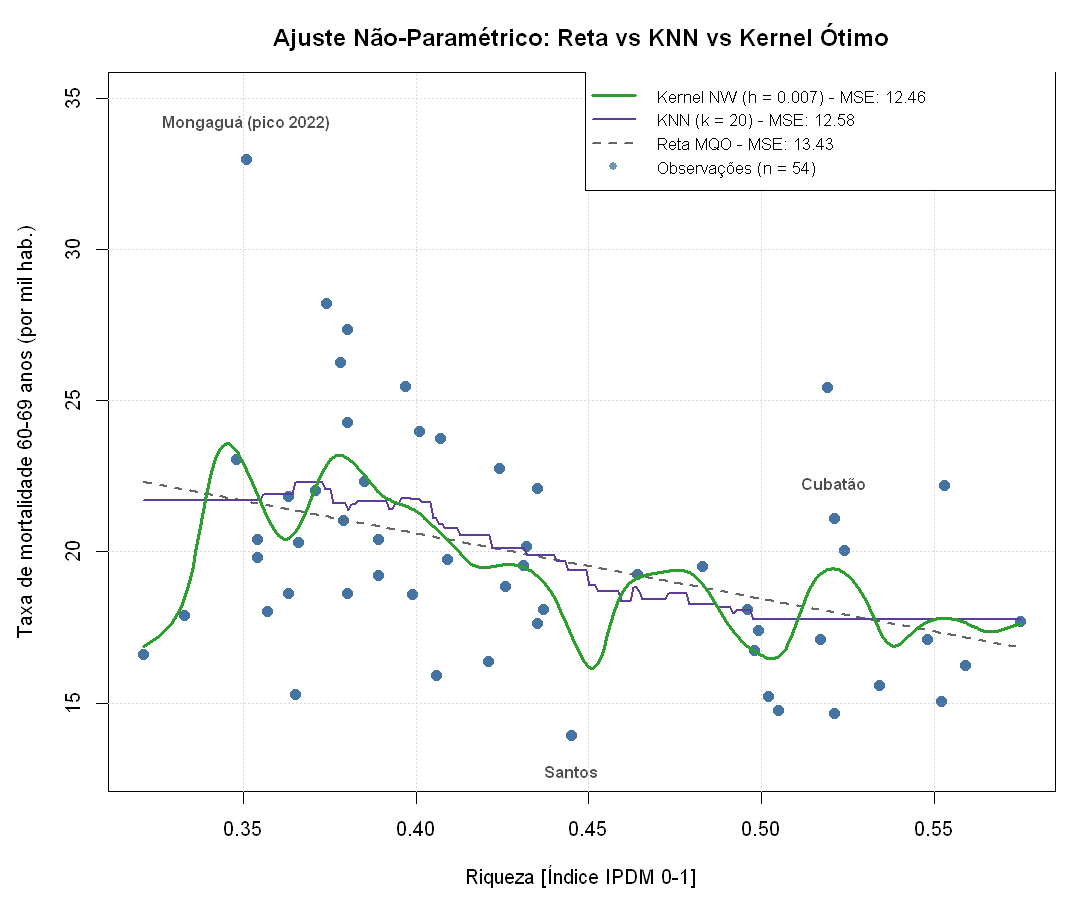

In [3]:
# =============================================================
# 3. FIGURA 1: AJUSTE REAL (RETA vs KNN vs KERNEL ÓTIMO)
# =============================================================
options(repr.plot.width = 9, repr.plot.height = 7.5)
par(mar = c(4.5, 4.5, 3, 1))

cazul <- "#276DC3"; claranja <- "#E66101"; cverde <- "#2CA02C"; croxo <- "#5E3C99"
g <- seq(min(x), max(x), length = 300)
pred_nw_melhor  <- sapply(g, nw, x = x, y = y, h = melhor_h)
pred_knn_melhor <- sapply(g, knn_reg, x = x, y = y, k = melhor_k)
pred_reta_g     <- sapply(g, reta, x = x, y = y)

plot(x, y, pch = 16, col = rgb(0.2, 0.4, 0.6, 0.7), cex = 1.2,
     xlab = "Riqueza [Índice IPDM 0-1]",
     ylab = "Taxa de mortalidade 60-69 anos (por mil hab.)",
     main = "Ajuste Não-Paramétrico: Reta vs KNN vs Kernel Ótimo",
     ylim = c(min(y) - 1, max(y) + 2))
grid(col = "gray85")
points(x, y, pch = 16, col = rgb(0.2, 0.4, 0.6, 0.7), cex = 1.2)
lines(g, pred_reta_g, col = "gray40", lwd = 2, lty = 2)
lines(g, pred_knn_melhor, col = croxo, lwd = 2.2, lty = 1)
lines(g, pred_nw_melhor, col = cverde, lwd = 2.8, lty = 1)

text(dados$riqueza[dados$municipio == "Santos" & dados$ano == 2024],
     dados$mortalidade_60_69[dados$municipio == "Santos" & dados$ano == 2024] - 1.2,
     "Santos", cex = 0.8, col = "gray30", font = 2)
text(dados$riqueza[dados$municipio == "Mongaguá" & dados$ano == 2022],
     dados$mortalidade_60_69[dados$municipio == "Mongaguá" & dados$ano == 2022] + 1.2,
     "Mongaguá (pico 2022)", cex = 0.8, col = "gray30", font = 2)
text(dados$riqueza[dados$municipio == "Cubatão" & dados$ano == 2022],
     dados$mortalidade_60_69[dados$municipio == "Cubatão" & dados$ano == 2022] + 1.2,
     "Cubatão", cex = 0.8, col = "gray30", font = 2)

legend("topright",
       legend = c(
         paste0("Kernel NW (h = ", round(melhor_h, 4), ") - MSE: ", round(min(cv_kernel), 2)),
         paste0("KNN (k = ", melhor_k, ") - MSE: ", round(min(cv_knn), 2)),
         paste0("Reta MQO - MSE: ", round(cv_reta, 2)),
         "Observações (n = 54)"
       ),
       col = c(cverde, croxo, "gray40", rgb(0.2, 0.4, 0.6, 0.7)),
       lty = c(1, 1, 2, NA), pch = c(NA, NA, NA, 16),
       lwd = c(2.8, 2.2, 2, NA), bty = "o", bg = "white", cex = 0.85)


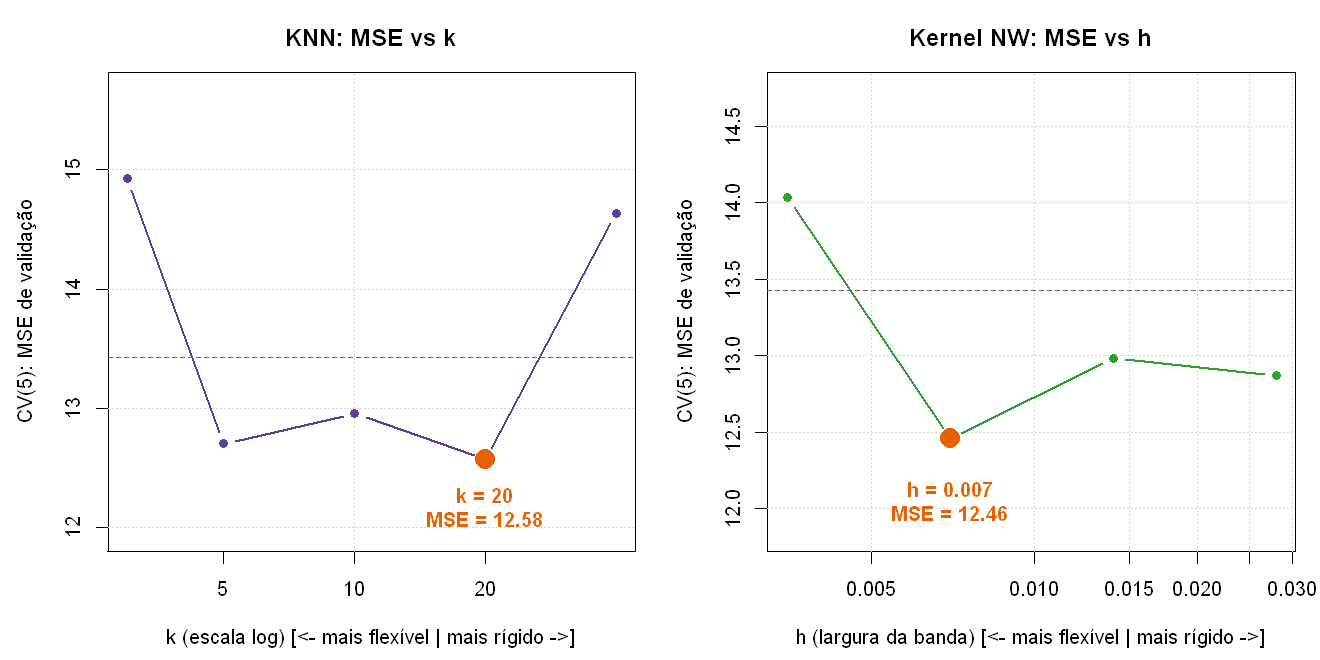

In [4]:
# =============================================================
# 4. FIGURA 2: CURVAS EM U DE VALIDAÇÃO CRUZADA
# =============================================================
options(repr.plot.width = 11, repr.plot.height = 5.5)
par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3, 1))

# KNN vs k
plot(ks, cv_knn, type = "b", log = "x", pch = 16, col = croxo, lwd = 2.2,
     xlab = "k (escala log) [<- mais flexível | mais rígido ->]",
     ylab = "CV(5): MSE de validação",
     main = "KNN: MSE vs k",
     ylim = range(c(cv_knn, cv_reta)) * c(0.95, 1.05))
grid(col = "gray85")
lines(ks, cv_knn, type = "b", pch = 16, col = croxo, lwd = 2.2)
abline(h = cv_reta, lty = 2, col = "gray40", lwd = 1.5)
points(melhor_k, min(cv_knn), pch = 16, cex = 2.2, col = claranja)
text(melhor_k, min(cv_knn) - 0.4, paste0("k = ", melhor_k, "\nMSE = ", round(min(cv_knn), 2)), col = claranja, font = 2)

# Kernel vs h
plot(hs, cv_kernel, type = "b", log = "x", pch = 16, col = cverde, lwd = 2.2,
     xlab = "h (largura da banda) [<- mais flexível | mais rígido ->]",
     ylab = "CV(5): MSE de validação",
     main = "Kernel NW: MSE vs h",
     ylim = range(c(cv_kernel, cv_reta)) * c(0.95, 1.05))
grid(col = "gray85")
lines(hs, cv_kernel, type = "b", pch = 16, col = cverde, lwd = 2.2)
abline(h = cv_reta, lty = 2, col = "gray40", lwd = 1.5)
points(melhor_h, min(cv_kernel), pch = 16, cex = 2.2, col = claranja)
text(melhor_h, min(cv_kernel) - 0.4, paste0("h = ", round(melhor_h, 4), "\nMSE = ", round(min(cv_kernel), 2)), col = claranja, font = 2)


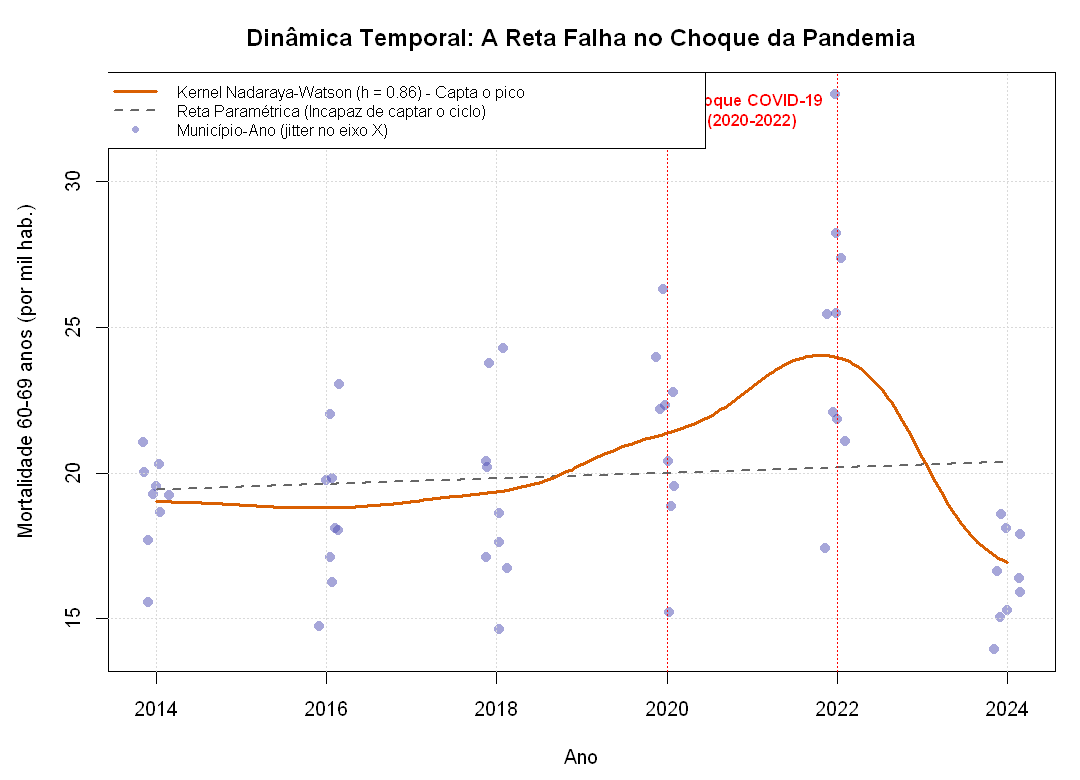

In [5]:
# =============================================================
# 5. FIGURA 4: A DINÂMICA TEMPORAL (ANO vs MORTALIDADE)
# =============================================================
options(repr.plot.width = 9, repr.plot.height = 6.5)
par(mar = c(4.5, 4.5, 3, 1))

x_ano <- dados$ano
y_ano <- dados$mortalidade_60_69
h_ano <- 0.86
g_ano <- seq(2014, 2024, length = 200)

pred_nw_ano <- sapply(g_ano, nw, x = x_ano, y = y_ano, h = h_ano)
m_reta_ano  <- lm(y_ano ~ x_ano)
pred_reta_ano <- predict(m_reta_ano, newdata = data.frame(x_ano = g_ano))

plot(jitter(x_ano, 0.4), y_ano, pch = 16, col = rgb(0.3, 0.3, 0.7, 0.5), cex = 1.1,
     xlab = "Ano", ylab = "Mortalidade 60-69 anos (por mil hab.)",
     main = "Dinâmica Temporal: A Reta Falha no Choque da Pandemia",
     xaxt = "n")
axis(1, at = seq(2014, 2024, by = 2))
grid(col = "gray85")
lines(g_ano, pred_reta_ano, col = "gray40", lwd = 2, lty = 2)
lines(g_ano, pred_nw_ano, col = "#D95F02", lwd = 3)

abline(v = c(2020, 2022), lty = 3, col = "red")
text(2021, max(y_ano) - 0.5, "Choque COVID-19\n(2020-2022)", col = "red", cex = 0.85, font = 2)

legend("topleft",
       legend = c(
         "Kernel Nadaraya-Watson (h = 0.86) - Capta o pico",
         "Reta Paramétrica (Incapaz de captar o ciclo)",
         "Município-Ano (jitter no eixo X)"
       ),
       col = c("#D95F02", "gray40", rgb(0.3, 0.3, 0.7, 0.5)),
       lty = c(1, 2, NA), pch = c(NA, NA, 16), lwd = c(3, 2, NA),
       bty = "o", bg = "white", cex = 0.82)


## Diagnóstico da Relação

> **Frase de diagnóstico da relação:**  
> A relação entre Riqueza e Mortalidade 60-69 anos NÃO é puramente uma reta. Ela apresenta um patamar elevado de mortalidade em municípios com índice de riqueza entre 0,35 e 0,42 (Itanhaém, Mongaguá e Peruíbe com taxas atingindo 23 a 32 por mil), uma queda acentuada em cidades de alta renda (Santos com mortalidade abaixo de 15 por mil), mas um repique não-linear intermediário em Cubatão (onde a riqueza é alta, ~0,51, mas a mortalidade chega a 21 por mil devido ao polo industrial). Por capturar esses patamares e inflexões locais sem forçar uma inclinação constante, o Kernel com $h = 0,0070$ supera o MQO com menor MSE de validação cruzada (12,46 vs 13,43).
